# 03 – Treinamento e Comparação de Modelos (Pessoa 2)
**Projeto 2 – Análise de Sentimentos B2W-Reviews01 | IFPB – Inteligência Artificial (Unidade 3)**

Objetivos: comparar **4 representações** (BoW/TF-IDF × unigramas/bigramas) e **4 classificadores** (Naive Bayes, Regressão Logística padrão e `balanced`, Linear SVM), com divisão estratificada 80/20 e **sem data leakage** (`fit` só em `X_train`).

Métrica principal: **F1-Macro** (as classes são desbalanceadas: 61,8% Positivo, 25,7% Negativo, 12,5% Neutro).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # raiz do projeto

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.models import *
from src.models import REPORTS_DIR
sns.set_theme(style="whitegrid")
FIG = REPORTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)

## 1. Carga e divisão estratificada 80/20

In [2]:
df, X_train, X_test, y_train, y_test = get_split()
print(f"Corpus: {len(df):,} | Treino: {len(X_train):,} | Teste: {len(X_test):,}")
pd.DataFrame({
    "treino_%": y_train.map(ID_TO_SENTIMENT).value_counts(normalize=True).mul(100).round(2),
    "teste_%":  y_test.map(ID_TO_SENTIMENT).value_counts(normalize=True).mul(100).round(2)})

Corpus: 126,690 | Treino: 101,352 | Teste: 25,338


,treino_%,teste_%
sentiment_id,,
Positivo,61.76,61.76
Negativo,25.73,25.73
Neutro,12.50,12.51


## 2. Experimentos: 4 representações × 4 classificadores
O vetorizador é ajustado (`fit_transform`) **apenas em `X_train`**; em `X_test` usa-se só `transform`.

In [3]:
results, vecs, models = run_experiments(X_train, X_test, y_train, y_test)
res = pd.DataFrame(results).drop(columns="confusion_matrix")
cols = ["representation","classifier","n_features","accuracy","f1_macro","f1_Negativo","f1_Neutro","f1_Positivo",
        "recall_Negativo","recall_Neutro","recall_Positivo","fit_seconds"]
tabela = res[cols].sort_values("f1_macro", ascending=False).reset_index(drop=True)
tabela.round(4)

bow_uni    nb          acc=0.7952 F1-macro=0.6770 (0.0s)
bow_uni    logreg      acc=0.8183 F1-macro=0.6684 (6.1s)
bow_uni    logreg_bal  acc=0.7669 F1-macro=0.6902 (7.0s)
bow_uni    svm_bal     acc=0.7910 F1-macro=0.6754 (107.4s)
bow_bi     nb          acc=0.8143 F1-macro=0.7073 (0.0s)
bow_bi     logreg      acc=0.8302 F1-macro=0.6978 (13.6s)
bow_bi     logreg_bal  acc=0.8006 F1-macro=0.7069 (14.9s)
bow_bi     svm_bal     acc=0.7958 F1-macro=0.6767 (202.9s)
tfidf_uni  nb          acc=0.8103 F1-macro=0.5874 (0.0s)
tfidf_uni  logreg      acc=0.8319 F1-macro=0.6755 (3.1s)
tfidf_uni  logreg_bal  acc=0.7681 F1-macro=0.6981 (4.5s)
tfidf_uni  svm_bal     acc=0.8035 F1-macro=0.6937 (5.8s)
tfidf_bi   nb          acc=0.8271 F1-macro=0.5969 (0.0s)
tfidf_bi   logreg      acc=0.8452 F1-macro=0.6993 (6.0s)
tfidf_bi   logreg_bal  acc=0.7992 F1-macro=0.7233 (7.3s)
tfidf_bi   svm_bal     acc=0.8221 F1-macro=0.7100 (6.7s)


,representation,classifier,n_features,accuracy,f1_macro,f1_Negativo,f1_Neutro,f1_Positivo,recall_Negativo,recall_Neutro,recall_Positivo,fit_seconds
0,tfidf_bi,logreg_bal,78918,0.7992,0.7233,0.8634,0.4398,0.8666,0.8917,0.5484,0.8114,7.3
1,tfidf_bi,svm_bal,78918,0.8221,0.7100,0.8610,0.3779,0.8911,0.8913,0.3588,0.8871,6.7
2,bow_bi,nb,78918,0.8143,0.7073,0.8404,0.3914,0.8903,0.8666,0.3932,0.8779,0.0
3,bow_bi,logreg_bal,78918,0.8006,0.7069,0.8534,0.3948,0.8725,0.8727,0.4418,0.8432,14.9
4,tfidf_bi,logreg,78918,0.8452,0.6993,0.8729,0.3193,0.9058,0.9072,0.2256,0.9448,6.0
5,tfidf_uni,logreg_bal,15978,0.7681,0.6981,0.8424,0.4100,0.8419,0.8627,0.5614,0.7705,4.5
6,bow_bi,logreg,78918,0.8302,0.6978,0.8602,0.3359,0.8973,0.8753,0.2745,0.9239,13.6
7,tfidf_uni,svm_bal,15978,0.8035,0.6937,0.8355,0.3663,0.8793,0.8635,0.3664,0.8670,5.8
8,bow_uni,logreg_bal,15978,0.7669,0.6902,0.8260,0.3980,0.8466,0.8367,0.5270,0.7864,7.0
9,bow_uni,nb,15978,0.7952,0.6770,0.8161,0.3360,0.8790,0.8293,0.3332,0.8746,0.0


### 2.1 F1-Macro por configuração

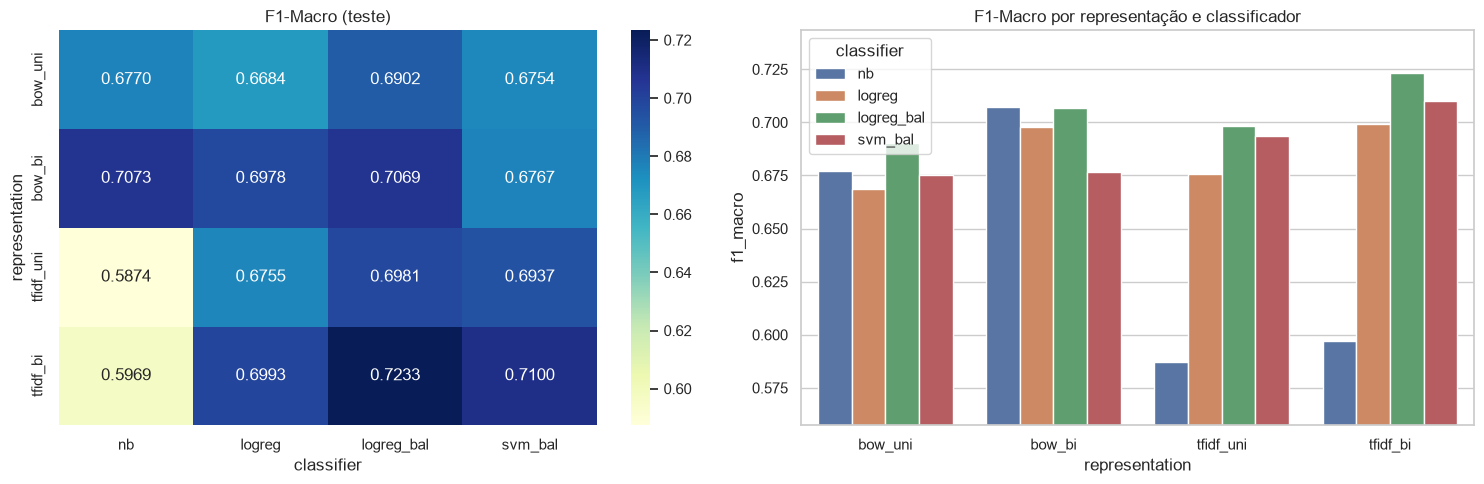

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
piv = res.pivot(index="representation", columns="classifier", values="f1_macro").loc[list(REPRESENTATIONS), list(CLASSIFIERS)]
sns.heatmap(piv, annot=True, fmt=".4f", cmap="YlGnBu", ax=ax[0]); ax[0].set_title("F1-Macro (teste)")
sns.barplot(data=res, x="representation", y="f1_macro", hue="classifier", ax=ax[1])
ax[1].set_ylim(res.f1_macro.min() - 0.03, res.f1_macro.max() + 0.02); ax[1].set_title("F1-Macro por representação e classificador")
plt.tight_layout(); plt.savefig(FIG / "09_f1_macro_comparacao.png", dpi=300); plt.show()

### 2.2 Efeitos isolados: BoW vs TF-IDF, uni vs bigramas, classificadores

In [5]:
res["tipo"] = res.representation.str.split("_").str[0]
res["ngram"] = res.representation.str.split("_").str[1].map({"uni": "unigramas", "bi": "uni+bigramas"})
for col in ["tipo", "ngram", "classifier"]:
    print(res.groupby(col)[["accuracy", "f1_macro", "f1_Neutro"]].mean().round(4), "\n")

       accuracy  f1_macro  f1_Neutro
tipo                                
bow      0.8015    0.6875     0.3495
tfidf    0.8134    0.6730     0.2871 

              accuracy  f1_macro  f1_Neutro
ngram                                      
uni+bigramas    0.8168    0.6898     0.3286
unigramas       0.7982    0.6707     0.3080 

            accuracy  f1_macro  f1_Neutro
classifier                               
logreg        0.8314    0.6853     0.3024
logreg_bal    0.7837    0.7046     0.4107
nb            0.8117    0.6422     0.2086
svm_bal       0.8031    0.6890     0.3516 



### 2.3 Melhor configuração: matriz de confusão e F1 por classe

{'representation': 'tfidf_bi', 'classifier': 'logreg_bal', 'accuracy': 0.7991948851527351, 'f1_macro': 0.7232857238195942}


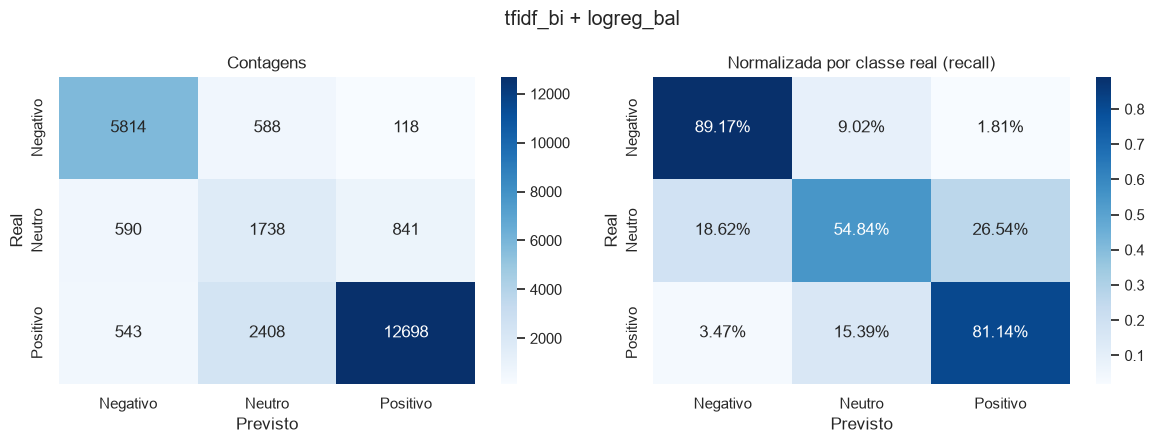

In [6]:
best = tabela.iloc[0]; print(best[["representation","classifier","accuracy","f1_macro"]].to_dict())
cm = np.array(next(r for r in results if r["representation"] == best.representation and r["classifier"] == best.classifier)["confusion_matrix"])
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax[0]); ax[0].set_title("Contagens")
sns.heatmap(cmn, annot=True, fmt=".2%", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax[1]); ax[1].set_title("Normalizada por classe real (recall)")
for a in ax: a.set_xlabel("Previsto"); a.set_ylabel("Real")
plt.suptitle(f"{best.representation} + {best.classifier}"); plt.tight_layout()
plt.savefig(FIG / "10_matriz_confusao_melhor_modelo.png", dpi=300); plt.show()

## 3. Ajuste de hiperparâmetros (`GridSearchCV`, F1-Macro, 3 folds estratificados)
Rodado **apenas em `X_train`**, dentro de um `Pipeline` (o vetorizador é refeito em cada fold, sem vazar vocabulário/IDF da validação). Usa-se a melhor representação da seção 2 para cada classificador.

In [7]:
rep_best = best.representation
rows = []
for clf in CLASSIFIERS:
    gs = tune(X_train, y_train, rep_best, clf)
    m = evaluate(y_test, gs.best_estimator_.predict(X_test))
    base = res[(res.representation == rep_best) & (res.classifier == clf)].f1_macro.iloc[0]
    rows.append({"classificador": clf, "melhor_param": gs.best_params_, "cv_f1_macro": round(gs.best_score_, 4),
                 "teste_f1_padrao": round(base, 4), "teste_f1_ajustado": round(m["f1_macro"], 4)})
pd.DataFrame(rows)

,classificador,melhor_param,cv_f1_macro,teste_f1_padrao,teste_f1_ajustado
0,nb,{'clf__alpha': 0.1},0.6800,0.5969,0.6851
1,logreg,{'clf__C': 3},0.7010,0.6993,0.7006
2,logreg_bal,{'clf__C': 1},0.7171,0.7233,0.7233
3,svm_bal,{'clf__C': 0.1},0.7248,0.7100,0.7318


## 4. Termos mais influentes (coeficientes da Regressão Logística)
Em cada classe, os termos com maior coeficiente positivo são os que mais empurram a previsão para ela.

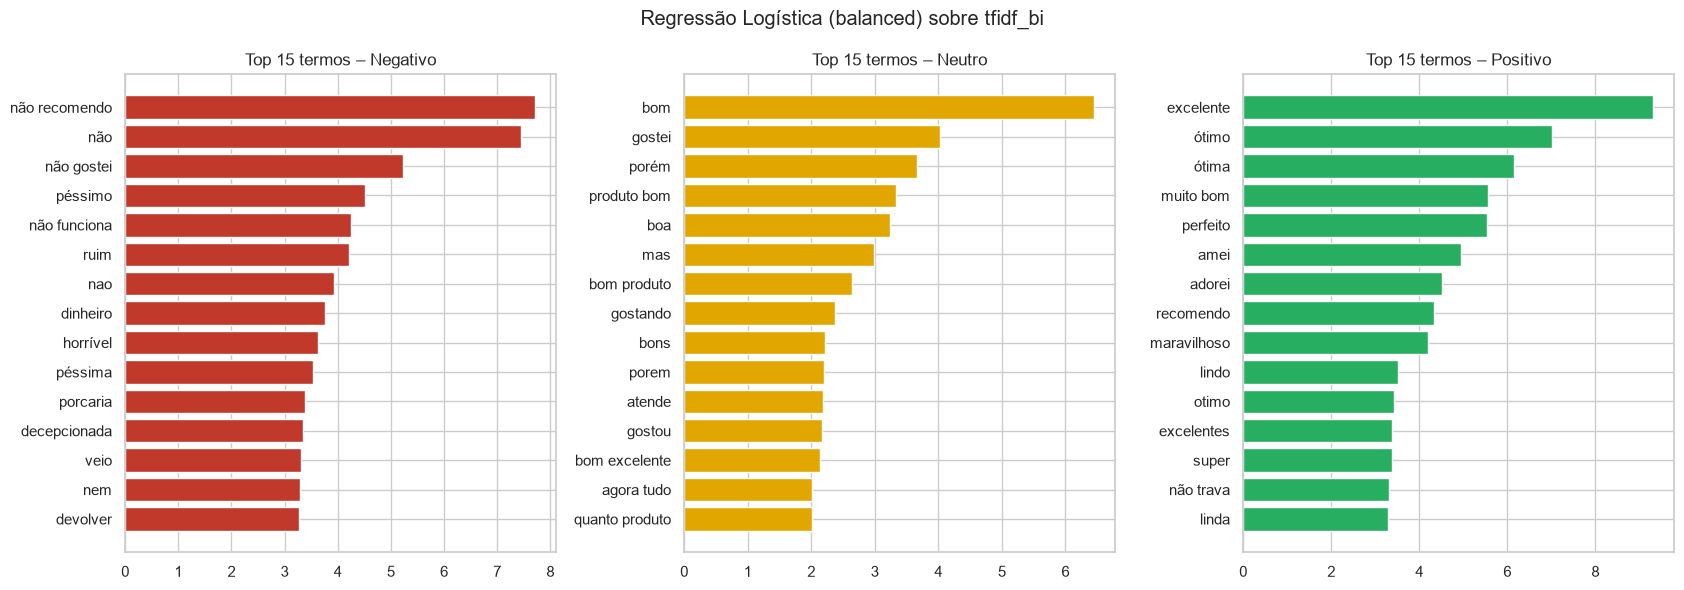

Negativo -> não recomendo, não, não gostei, péssimo, não funciona, ruim, nao, dinheiro, horrível, péssima
Neutro -> bom, gostei, porém, produto bom, boa, mas, bom produto, gostando, bons, porem
Positivo -> excelente, ótimo, ótima, muito bom, perfeito, amei, adorei, recomendo, maravilhoso, lindo


In [8]:
vec, lr = vecs[rep_best], models[(rep_best, "logreg_bal")]
terms = np.array(vec.get_feature_names_out())
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
colors = {"Negativo": "#c0392b", "Neutro": "#e1a600", "Positivo": "#27ae60"}
for i, name in enumerate(LABEL_NAMES):
    idx = np.argsort(lr.coef_[i])[-15:]
    axes[i].barh(terms[idx], lr.coef_[i][idx], color=colors[name]); axes[i].set_title(f"Top 15 termos – {name}")
plt.suptitle(f"Regressão Logística (balanced) sobre {rep_best}"); plt.tight_layout()
plt.savefig(FIG / "11_termos_mais_influentes.png", dpi=300); plt.show()
for i, name in enumerate(LABEL_NAMES):
    print(name, "->", ", ".join(terms[np.argsort(lr.coef_[i])[-10:][::-1]]))

## 5. (Bônus) Negation marking em unigramas
Compara `não gostei` → `não_gostei` com unigramas contra o texto padrão (unigramas e bigramas). O split usa a mesma semente, portanto o conjunto de teste é idêntico.

In [9]:
df_n, Xtr_n, Xte_n, ytr_n, yte_n = get_split(mark_negation=True)
assert (Xte_n.index == X_test.index).all()    # mesmo conjunto de teste
r_n, _, _ = run_experiments(Xtr_n, Xte_n, ytr_n, yte_n, reps=["bow_uni", "tfidf_uni"], verbose=False)
neg = pd.DataFrame(r_n)[["representation","classifier","f1_macro"]].rename(columns={"f1_macro": "f1_com_marcacao"})
comp = res[res.representation.isin(["bow_uni","tfidf_uni","bow_bi","tfidf_bi"])][["representation","classifier","f1_macro"]]
unig = comp[comp.representation.isin(["bow_uni","tfidf_uni"])].rename(columns={"f1_macro": "f1_unigrama_padrao"})
bi = comp[comp.representation.isin(["bow_bi","tfidf_bi"])].assign(representation=lambda d: d.representation.str.replace("_bi","_uni")).rename(columns={"f1_macro": "f1_bigrama_padrao"})
out = neg.merge(unig, on=["representation","classifier"]).merge(bi, on=["representation","classifier"])
out["ganho_marcacao_vs_unigrama"] = (out.f1_com_marcacao - out.f1_unigrama_padrao).round(4)
out.round(4)

,representation,classifier,f1_com_marcacao,f1_unigrama_padrao,f1_bigrama_padrao,ganho_marcacao_vs_unigrama
0,bow_uni,nb,0.6888,0.6770,0.7073,0.0118
1,bow_uni,logreg,0.6808,0.6684,0.6978,0.0124
2,bow_uni,logreg_bal,0.6962,0.6902,0.7069,0.0061
3,bow_uni,svm_bal,0.6840,0.6754,0.6767,0.0086
4,tfidf_uni,nb,0.5986,0.5874,0.5969,0.0113
5,tfidf_uni,logreg,0.6852,0.6755,0.6993,0.0097
6,tfidf_uni,logreg_bal,0.7054,0.6981,0.7233,0.0073
7,tfidf_uni,svm_bal,0.7023,0.6937,0.7100,0.0086


## 6. Artefatos gerados
Os modelos e vetorizadores são salvos em `models_saved/`, e as métricas em `reports/model_results.json`, ao executar na raiz do projeto:
```powershell
python -m src.models
```
- `vec_<rep>.joblib` e `<rep>__<clf>.joblib`: as 16 combinações (representação × classificador), com hiperparâmetros padrão.
- `tuned__<clf>.joblib`: *pipelines* ajustados por validação cruzada (`GridSearchCV`).
- `best_pipeline.joblib`: modelo final, escolhido pelo F1-Macro de validação cruzada (nunca pelo teste).

Para prever um texto novo: `load_artifacts(rep, clf)` + `predict_with_confidence(vec, model, preprocess_text(texto))`.